# 01 — Data Preparation
**Covers rubric steps 1–3:** describe the data, check data quality, document preparation.

**Input:** `data/raw/survey_results_public.csv` (untouched download)
**Output:** `data/processed/us_fulltime_clean.csv`

Run top to bottom. Every filtering or cleaning choice gets a markdown cell explaining *why*.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## 1. Describe the data
Source, size, and what one row represents (one survey respondent).

In [2]:
raw = pd.read_csv("../data/raw/survey_results_public.csv", low_memory=False)
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (49191, 172)


,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,AILearnHow,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,PurchaseInfluence,TechEndorseIntro,TechEndorse_1,TechEndorse_2,TechEndorse_3,TechEndorse_4,TechEndorse_5,TechEndorse_6,TechEndorse_7,...,AIAgentChange,AIAgent_Uses,AgentUsesGeneral,AIAgentImpactSomewhat agree,AIAgentImpactNeutral,AIAgentImpactSomewhat disagree,AIAgentImpactStrongly agree,AIAgentImpactStrongly disagree,AIAgentChallengesNeutral,AIAgentChallengesSomewhat disagree,AIAgentChallengesStrongly agree,AIAgentChallengesSomewhat agree,AIAgentChallengesStrongly disagree,AIAgentKnowledge,AIAgentKnowWrite,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps,14.0,"Developer, mobile",20 to 99 employees,People manager,Remote,"Yes, I influenced the purchase of a substantia...",Work,10.0,7.0,9.0,6.0,3.0,11.0,12.0,...,Not at all or minimally,Software engineering,NaN,AI agents have increased my productivity.;AI a...,AI agents have helped me automate repetitive t...,NaN,NaN,NaN,I am concerned about the accuracy of the infor...,Integrating AI agents with my existing tools a...,The cost of using certain AI agent platforms i...,NaN,NaN,NaN,NaN,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps,10.0,"Developer, back-end",500 to 999 employees,Individual contributor,"Hybrid (some in-person, leans heavy to flexibi...",No,Personal Project,13.0,1.0,2.0,9.0,4.0,3.0,12.0,...,Not at all or minimally,NaN,NaN,NaN,NaN,NaN,NaN,NaN,It takes significant time and effort to learn ...,NaN,I am concerned about the accuracy of the infor...,Integrating AI agents with my existing tools a...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps;Technical ...,12.0,"Developer, front-end",NaN,NaN,NaN,No,Work,12.0,2.0,3.0,7.0,5.0,10.0,13.0,...,"Yes, somewhat",Software engineering,Multi-platform search enablement,AI agents have increased my productivity.;AI a...,AI agents have improved the quality of my code...,AI agents have improved collaboration within m...,NaN,NaN,It takes significant time and effort to learn ...,My company's IT and/or InfoSec teams have stri...,NaN,I am concerned about the accuracy of the infor...,NaN,Redis,NaN,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps;Videos (no...,5.0,"Developer, back-end","10,000 or mor

In [3]:
for c in ["Employment", "EmploymentAddl", "RemoteWork", "ICorPM", "MainBranch"]:
    print(f"--- {c} ---")
    print(raw[c].value_counts(dropna=False), "\n")

--- Employment ---
Employment
Employed                                                33750
Independent contractor, freelancer, or self-employed     6708
Student                                                  4428
Not employed                                             2227
NaN                                                       852
Retired                                                   708
I prefer not to say                                       518
Name: count, dtype: int64 

--- EmploymentAddl ---
EmploymentAddl
None of the above                                                                                                                                             18613
Caring for dependents (children, elderly, etc.)                                                                                                                5315
Engaged in paid work (20-29 hours per week)                                                                                                   

In [4]:
# Variables we plan to use - verify every name against data/docs/survey_results_schema.csv
cols = ["ResponseId", "ConvertedCompYearly", "WorkExp", "YearsCode", "DevType",
        "RemoteWork", "Employment", "Country", "EdLevel", "OrgSize", "Age"]
missing_cols = [c for c in cols if c not in raw.columns]
print("Columns not found (check schema for the 2025 name):", missing_cols)

Columns not found (check schema for the 2025 name): []


In [5]:
# Data types and a peek at each variable
for c in [c for c in cols if c in raw.columns]:
    print(f"--- {c} ({raw[c].dtype}) ---")
    print(raw[c].value_counts(dropna=False).head(8), "\n")

--- ResponseId (int64) ---
ResponseId
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1
Name: count, dtype: int64 

--- ConvertedCompYearly (float64) ---
ConvertedCompYearly
NaN         25244
69609.0       328
58007.0       270
92812.0       269
81210.0       266
116015.0      263
150000.0      235
200000.0      220
Name: count, dtype: int64 

--- WorkExp (float64) ---
WorkExp
NaN     6298
10.0    2885
3.0     2613
5.0     2563
1.0     2453
2.0     2408
15.0    2226
4.0     2166
Name: count, dtype: int64 

--- YearsCode (float64) ---
YearsCode
NaN     6149
10.0    3108
15.0    2540
20.0    2497
5.0     2267
8.0     2113
6.0     1925
25.0    1832
Name: count, dtype: int64 

--- DevType (str) ---
DevType
Developer, full-stack                            12351
Developer, back-end                               6453
NaN                                               5511
Student                                           3008
Architect, software or solutions                  2684
Develop

### Variables used

| Variable | Survey question (2025) | Type | Notes |
|---|---|---|---|
| `ConvertedCompYearly` | Derived from `CompTotal`: "current total annual compensation (salary, bonuses, and perks, before taxes and deductions)" | Numeric, USD/year | Target. Converted to USD by Stack Overflow (June 25, 2025 rate); hourly workers asked to estimate a yearly equivalent |
| `WorkExp` | "How many years of professional work experience do you have?" | Numeric, years | Whole numbers; respondents told to leave blank if the answer is 0 |
| `YearsCode` | "Including any education, how many years have you been coding in total?" | Numeric, years | Includes school and hobby coding |
| `DevType` | "Which of the following describes your current job…?" | Categorical, single-select | Grouped into 9 role families |
| `RemoteWork` | "Which best describes your current work situation?" | Categorical, 5 options | Grouped into Remote / Hybrid / In-person |
| `Employment` | "Which of the following best describes your current employment status?" | Categorical, single-select | Filtered to "Employed" |
| `Country` | "Where do you live?" | Categorical | Filtered to United States of America |
| `EdLevel` | Highest level of formal education completed | Categorical | |
| `OrgSize` | Approximate number of employees at primary employer | Categorical (ordered) | |
| `ICorPM` | "Are you an individual contributor or people manager?" | Categorical | |
| `Age` | "What is your age?" | Categorical (ranges) | |

One row = one survey respondent. Raw data: 49,191 rows × 172 columns.

## 2. Define the population
Filter step by step and record the row count after each step. Check the exact country and employment labels in the output above before running.

In [6]:
funnel = [("All respondents", len(raw))]

us = raw[raw["Country"] == "United States of America"]
funnel.append(("United States", len(us)))

# 2025 has no full-time option; "Employed" excludes contractors/freelancers,
# whose reported pay may be business income rather than salary
ft = us[us["Employment"] == "Employed"]
funnel.append(("Employed (not self-employed)", len(ft)))

paid = ft[ft["ConvertedCompYearly"].notna()].copy()
funnel.append(("Reported compensation", len(paid)))

pd.DataFrame(funnel, columns=["Step", "Rows remaining"])

,Step,Rows remaining
0,All respondents,49191
1,United States,7233
2,Employed (not self-employed),5413
3,Reported compensation,4532


## 3. Data quality
### 3a. Missing compensation — is it random?
Compare full-time U.S. respondents who reported pay with those who did not.

In [7]:
ft = ft.copy()
ft["reported_pay"] = ft["ConvertedCompYearly"].notna()
print(ft["reported_pay"].value_counts(normalize=True))

for c in ["RemoteWork", "EdLevel"]:
    print(pd.crosstab(ft[c], ft["reported_pay"], normalize="columns").round(3), "\n")

reported_pay
True     0.837244
False    0.162756
Name: proportion, dtype: float64
reported_pay                                        False  True 
RemoteWork                                                      
Hybrid (some in-person, leans heavy to flexibil...  0.138  0.131
Hybrid (some remote, leans heavy to in-person)      0.178  0.175
In-person                                           0.221  0.148
Remote                                              0.373  0.463
Your choice (very flexible, you can come in whe...  0.090  0.083 

reported_pay                                        False  True 
EdLevel                                                         
Associate degree (A.A., A.S., etc.)                 0.039  0.045
Bachelor’s degree (B.A., B.S., B.Eng., etc.)        0.479  0.559
Master’s degree (M.A., M.S., M.Eng., MBA, etc.)     0.254  0.201
Other (please specify):                             0.006  0.003
Primary/elementary school                           0.010  0.003
Profes

In [8]:
summary = ft.groupby("reported_pay").agg(
    n=("ResponseId", "count"),
    median_WorkExp=("WorkExp", "median"),
    pct_remote=("RemoteWork", lambda s: (s == "Remote").mean()),
    pct_manager=("ICorPM", lambda s: (s == "People manager").mean()),
).round(2)
summary

,n,median_WorkExp,pct_remote,pct_manager
reported_pay,,,,
False,881,17.0,0.36,0.16
True,4532,14.0,0.46,0.13


**Interpretation.** Among 5,413 employed U.S. respondents, 881 (16%) did not report compensation.
Non-reporters had a median of 17 years of experience vs. 14 for the 4,532 reporters, 36% vs. 46% worked
fully remote, and 16% vs. 13% were people managers (they were also more often in-person: 22% vs. 15%).
Non-reporters skew more senior and less remote, so our sample may over-represent remote developers and
under-represent experienced, in-person ones; dropping them could bias pay comparisons by remote status and
experience somewhat, and we note this as a limitation.

### 3b. Duplicates

In [9]:
print("Duplicate ResponseIds:", paid["ResponseId"].duplicated().sum())
print("Fully identical rows:", paid.duplicated().sum())

Duplicate ResponseIds: 0


Fully identical rows: 0


No duplicate `ResponseId`s (0) or fully identical rows (0) were found among the 4,532 respondents
who reported compensation, so no rows were removed.

### 3c. Extreme compensation values
Look before deciding. Pay is right-skewed, so use a log scale.

count    4.532000e+03
mean     1.763235e+05
std      1.808517e+05
min      3.000000e+00
1%       3.137380e+03
5%       5.900000e+04
50%      1.500000e+05
95%      3.500000e+05
99%      6.419000e+05
max      9.000000e+06
Name: ConvertedCompYearly, dtype: float64


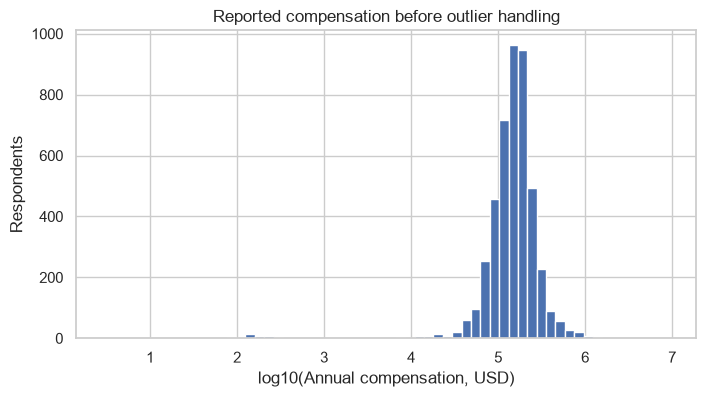

In [10]:
print(paid["ConvertedCompYearly"].describe(percentiles=[.01, .05, .5, .95, .99]))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(paid["ConvertedCompYearly"].clip(lower=1)), bins=60)
ax.set_xlabel("log10(Annual compensation, USD)")
ax.set_ylabel("Respondents")
ax.set_title("Reported compensation before outlier handling")
plt.show()

In [11]:
# Outlier rule - CHOOSE ONE, justify it in markdown, and report how many rows it affects.
LOW, HIGH = 10_000, paid["ConvertedCompYearly"].quantile(0.99)
outside = ~paid["ConvertedCompYearly"].between(LOW, HIGH)
print(f"Rows outside [{LOW:,.0f}, {HIGH:,.0f}]: {outside.sum()} ({outside.mean():.1%})")

paid = paid[~outside].copy()
funnel.append(("After outlier rule", len(paid)))

Rows outside [10,000, 641,900]: 97 (2.1%)


**Outlier rule.** We kept compensation between $10,000 and the 99th percentile (~$642,000),
removing 97 rows (2.1%). Values below $10,000 (minimum: $3) are implausible as annual U.S.
pay for an employed developer and likely reflect monthly amounts or data-entry errors. The top
1% includes clear errors such as $9,000,000. Because the survey defines compensation as total
pay (salary, bonuses, and perks), some legitimately high values remain; since our comparisons
use medians, results are not sensitive to the exact cutoff.

## 4. Preparation
### 4a. Experience stored as text

In [12]:
# In 2025, WorkExp and YearsCode are already numeric, so no text recoding is needed
paid["WorkExp_num"] = paid["WorkExp"]
paid["YearsCode_num"] = paid["YearsCode"]
print(paid[["WorkExp_num", "YearsCode_num"]].describe())
print("Missing WorkExp:", paid["WorkExp_num"].isna().sum())

       WorkExp_num  YearsCode_num
count  4400.000000    4426.000000
mean     15.953409      20.282648
std      10.438068      11.216527
min       1.000000       1.000000
25%       8.000000      11.000000
50%      14.000000      18.000000
75%      23.000000      28.000000
max      58.000000      58.000000
Missing WorkExp: 35


In [13]:
# Blank WorkExp: the questionnaire says to leave it blank if the answer is 0
blank = paid["WorkExp"].isna()
print("Blank WorkExp:", blank.sum(), f"({blank.mean():.1%})")
print(paid.groupby(blank)["ConvertedCompYearly"].median().rename({True: "blank", False: "not blank"}))

Blank WorkExp: 35 (0.8%)
WorkExp
not blank    150000.0
blank         64000.0
Name: ConvertedCompYearly, dtype: float64


**Experience.** In 2025, `WorkExp` and `YearsCode` are already numeric, so no text recoding is needed.
35 of 4,435 respondents (0.8%) left `WorkExp` blank. The questionnaire tells respondents to leave it blank
if the answer is 0, so blanks may mean 0 years rather than a skipped question (no one entered a value below 1).
Their median pay is $64,000 vs. $150,000 for everyone else, which is consistent with very junior developers.
Because we cannot tell a true 0 from a skipped answer, we treat blanks as missing (they are left out of the
experience bands) and note this as a limitation.

In [14]:
bins = [0, 2, 5, 10, 20, np.inf]
labels = ["0-2", "3-5", "6-10", "11-20", "20+"]
paid["exp_band"] = pd.cut(paid["WorkExp_num"], bins=bins, labels=labels, include_lowest=True)
paid["exp_band"].value_counts().sort_index()

exp_band
0-2       231
3-5       470
6-10      980
11-20    1440
20+      1279
Name: count, dtype: int64

In [15]:
remote_map = {
    "Remote": "Remote",
    "In-person": "In-person",
    "Hybrid (some remote, leans heavy to in-person)": "Hybrid",
    "Hybrid (some in-person, leans heavy to flexibility)": "Hybrid",
    "Your choice (very flexible, you can come in when you want or just as needed)": "Hybrid",
}
paid["RemoteWork_detail"] = paid["RemoteWork"]          # keep the original 5 options
paid["RemoteWork"] = paid["RemoteWork"].map(remote_map)  # 3 groups for comparisons
pd.crosstab(paid["RemoteWork_detail"], paid["RemoteWork"], margins=True)

RemoteWork,Hybrid,In-person,Remote,All
RemoteWork_detail,,,,
"Hybrid (some in-person, leans heavy to flexibility)",579,0,0,579
"Hybrid (some remote, leans heavy to in-person)",770,0,0,770
In-person,0,654,0,654
Remote,0,0,2048,2048
"Your choice (very flexible, you can come in when you want or just as needed)",367,0,0,367
All,1716,654,2048,4418


### 4b. Multi-select questions
Check whether `DevType` contains semicolon-separated answers, then choose and justify an approach.

In [16]:
multi = paid["DevType"].str.contains(";", na=False)
print(f"DevType multi-select rows: {multi.sum()} ({multi.mean():.1%})")

DevType multi-select rows: 0 (0.0%)


In [17]:
role_map = {
    "Developer, full-stack": "Full-stack developer",
    "Developer, back-end": "Back-end developer",
    "Developer, front-end": "Front-end / mobile developer",
    "Developer, mobile": "Front-end / mobile developer",
    "Developer, desktop or enterprise applications": "Desktop / embedded developer",
    "Developer, embedded applications or devices": "Desktop / embedded developer",
    "Architect, software or solutions": "Architect",
    "Engineering manager": "Management",
    "Senior executive (C-suite, VP, etc.)": "Management",
    "Product manager": "Management",
    "Data engineer": "Data / AI",
    "Data scientist": "Data / AI",
    "AI/ML engineer": "Data / AI",
    "Applied scientist": "Data / AI",
    "Data or business analyst": "Data / AI",
    "DevOps engineer or professional": "Infrastructure / ops",
    "Cloud infrastructure engineer": "Infrastructure / ops",
    "System administrator": "Infrastructure / ops",
    "Cybersecurity or InfoSec professional": "Infrastructure / ops",
    "Support engineer or analyst": "Infrastructure / ops",
}
paid["role_detail"] = paid["DevType"]                 # keep the original role
paid["role"] = paid["DevType"].map(role_map)
# Any answered role not in the map (Other, researcher, QA, rare roles) -> "Other"
paid.loc[paid["DevType"].notna() & paid["role"].isna(), "role"] = "Other"

print(paid["role"].value_counts())
print("Missing DevType:", paid["DevType"].isna().sum())

role
Full-stack developer            1473
Back-end developer               620
Other                            417
Desktop / embedded developer     376
Infrastructure / ops             346
Data / AI                        345
Management                       313
Architect                        280
Front-end / mobile developer     265
Name: count, dtype: int64
Missing DevType: 0


**Roles and work arrangement.** `DevType` is single-select in 2025 (0 rows contain ";"), so each respondent
has exactly one role. The 31 roles in our sample are grouped into 9 families so each group has 250+ respondents
(smallest: Front-end / mobile, 265), which keeps group medians stable; the original answer is kept in `role_detail`.
`RemoteWork` is grouped from 5 options into Remote / Hybrid / In-person, with "Your choice (very flexible)"
counted as Hybrid; the original answer is kept in `RemoteWork_detail`.

### 4c. Log compensation (for plots and models)

In [18]:
paid["log_pay"] = np.log(paid["ConvertedCompYearly"])
paid = paid.rename(columns={"ConvertedCompYearly": "pay"})

## 5. Save the processed dataset

In [19]:
keep = ["ResponseId", "pay", "log_pay", "WorkExp_num", "YearsCode_num", "exp_band",
        "role", "RemoteWork", "RemoteWork_detail", "EdLevel", "OrgSize", "Age"]
paid[keep].to_csv("../data/processed/us_fulltime_clean.csv", index=False)
print("Saved:", paid[keep].shape)
pd.DataFrame(funnel, columns=["Step", "Rows remaining"])

Saved: (4435, 12)


,Step,Rows remaining
0,All respondents,49191
1,United States,7233
2,Employed (not self-employed),5413
3,Reported compensation,4532
4,After outlier rule,4435
